# E96 · The snow pillow died in February: rebuilding April 1 snowpack from four imperfect sensors

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: twenty winters (water years 2006-2025) of daily records from the **University Camp SNOTEL station** (10,330 ft, Boulder Creek headwaters, Colorado): snow-pillow snow water equivalent as published and as first reported in real time, ultrasonic snow depth, storage-gauge precipitation and air temperature; the **hand-measured snow course** beside it; and the pillows of four neighbouring stations. USDA NRCS Air and Water Database, public domain |
| **You will learn** | Writing a **mass balance as a state-space model**: a weekly snow budget whose state (snow water, fresh-snow depth, a slow depth drift) is seen by sensors through **different functions** - the pillow directly, the depth sensor through a **latent density**, the gauge through a **catch ratio**, the course through its own **ratio to the pillow** · one **Kalman filter** written once and run both in PyTensor (inside `pm.Potential`, so NUTS samples 60 numbers while 1,560 states are integrated out) and in NumPy (for nowcasts and checks), with a unit test that they agree · `pm.Data` switches and nutpie's `with_data` to refit many variants from **one compilation** · a **two-fold backtest** in which the pillow dies in every season · why **one-step-ahead checks pass** while the **eight-week forecast is overconfident**, and the fix · what each sensor is worth · a **drought call** at 80% of median against the quick fixes people use · catching a **real pillow fault** (March 2014) with innovation gating |

## The setting

Most of the water used in the American West falls as snow and is stored, for months, in the mountains.
How much is up there on April 1 - close to the seasonal peak at many sites - is the number on which
reservoir operators, irrigation districts and city utilities plan the summer. Since the 1930s it has been
measured by hand on **snow courses**: a surveyor skis to a marked transect once a month, pushes a hollow
tube through the snowpack at a handful of points and weighs the cores (Church 1933). Since the late 1970s
the US Natural Resources Conservation Service (NRCS) has added **SNOTEL** stations: an automatic site
with a **snow pillow** (a fluid-filled bladder that weighs the snow above it and reports its **snow
water equivalent**, SWE), a storage **precipitation gauge**, a thermometer and, since the mid-2000s, an
**ultrasonic depth sensor** (Serreze et al. 1999).

Pillows fail. Ice layers bridge over them and hold weight off the bladder; fluid leaks; transducers drift;
a station loses power in a storm (Johnson & Marks 2004). When the pillow goes, the other instruments keep
running, but none of them measures SWE. The depth sensor sees depth, and SWE is depth times a **bulk
density** that rises through the winter as the snow settles (Sturm et al. 2010). The gauge sees
precipitation, but gauges catch snow badly in wind (Goodison et al. 1998; Rasmussen et al. 2012), some
of what falls is rain, and the snowpack loses water to melt and sublimation that no gauge records. The
snow course measures SWE well, but on a different patch of ground, and only once a month.

This is a **sensor fusion** problem, and its natural statistical form is a state-space model: one hidden
state - the water in the snowpack - evolving by a physical budget (snow in, melt out), with each sensor
a noisy window onto some function of it. The Kalman filter (Kalman 1960) does the fusion, and snow
hydrologists have used it for exactly this (Slater & Clark 2006). E13 used the filter to integrate out a
latent level so NUTS saw only a few variances; here the same trick lets PyMC fit a 20-season,
four-sensor model in well under a minute.

The question is concrete. A water manager wants to know on April 1 whether the snowpack at University
Camp is **below 80% of its 1991-2020 median** - we use that as an illustrative drought trigger - and the
pillow stopped reporting in early February. We cannot wait for a real outage at a convenient site, so we
**make one**: in every one of twenty winters we hide the pillow from February 5 onwards, rebuild April
1 from the other sensors, and compare with what the pillow actually said.

| part | question | tool |
|---|---|---|
| 1 | What do the four sensors see, and how often is the pillow record itself edited? | the AWDB data; published versus real-time values |
| 2 | How good are the quick fixes? | carry forward, percent-of-median persistence, neighbour ratios, depth times density |
| 3 | How do we write the fusion down? | a weekly snow budget as a state-space model; one Kalman filter for PyTensor and NumPy; prior predictive check |
| 4 | Does it fit, and does it forecast honestly? | two-fold backtest; one-week-ahead innovations; eight-week-ahead April 1 scores |
| 5 | Why were the first intervals too narrow? | a slowly drifting depth error, and its fix |
| 6 | What is each sensor worth? | refits with sensors removed, from one compiled model |
| 7 | Drought or not? | P(April 1 < 80% of median), against the quick fixes |
| 8 | Can the fusion catch a real fault? | the real-time pillow record of March 2014; innovation gating |

In [1]:
import logging
import sys
import time
import warnings
from types import SimpleNamespace

import arviz as az
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor
import pytensor.tensor as pt
from scipy.stats import norm

from pymc_challenges import data

sys.modules.pop("jax", None)          # ArviZ leaves a lazy JAX stub that Matplotlib would import in full
RANDOM_SEED = 96
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="arviz")
warnings.filterwarnings("ignore", message=".*Potential.*")
warnings.filterwarnings("ignore", message="Mean of empty slice")
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8e5bd0", "#c8384e"
INK, MUTED, LIGHT = "#0b0b0b", "#8a8984", "#d9d8d3"
MONTHS = mdates.DateFormatter("%b %d")
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, nutpie {nutpie.__version__}")

PyMC 6.3.2, ArviZ 1.3.0, nutpie 0.16.11


## 1 · One site, four windows on the same snowpack

The data come from the NRCS Air and Water Database through its public REST API, snapshotted by
`tools/build_e96_data.py`. University Camp sits at 10,330 ft near the University of Colorado's Mountain
Research Station, in the headwaters of Boulder Creek. It has two features that make it the right place for
this exercise: a snow course measured by hand since 1938 under a kilometre from the pillow, and a
pillow record that NRCS has rarely had to correct, so that the pillow can serve as the truth we hide and
then try to rebuild. Four neighbouring SNOTEL stations (2.6-32 km away) supply the neighbour baseline.

In [2]:
data.describe("e96_snotel_daily")
data.describe("e96_snow_course")
daily = data.load("e96_snotel_daily")
daily["date"] = pd.to_datetime(daily["date"])
course = data.load("e96_snow_course")
course["date"] = pd.to_datetime(course["date"])
uc = daily[daily.station_id == 838].set_index("date")
print(daily.groupby("station")[["elevation_ft"]].first().join(
    daily.groupby("station").wteq.count().rename("days")))
print(course[course.date >= "2005-10-01"].groupby("survey").swe.agg(["count", "median"]))

e96_snotel_daily: Daily SNOTEL records, water years 2006-2025, October 1 to June 30, for University Camp (station 838, 10,330 ft, Boulder Creek headwaters, Colorado) and four neighbours (Niwot 663, Lake Eldora 564, Wild Basin 1042, Bear Lake 322). Columns: station_id, station, elevation_ft, date, wteq (snow-pillow snow water equivalent as published, in), wteq_flag (QC flag: V validated, E edited/estimated), wteq_raw (the original real-time value before NRCS editing, in), wteq_median (1991-2020 median for that calendar day, in); for University Camp only: snwd (ultrasonic snow depth, in), prec (storage-gauge precipitation accumulated since October 1, in), tavg (daily mean air temperature, deg F), each with a _flag column.
  source: USDA NRCS National Water and Climate Center, SNOTEL network, through the Air and Water Database (AWDB) REST API (public domain, no key). An API snapshot written by tools/build_e96_data.py on 2026-11-04 - keep the cached CSV in data/ (NRCS re-edits published va

The snow course is surveyed four times a season, at the end of January, February, March and April, for
the reports of February 1, March 1, April 1 and May 1. Its median April 1 survey (17 in of water) is
higher than the pillow's April 1 median (15.4 in), a first sign that the course and the pillow do not
measure the same snow.

The published SNOTEL record is not raw data. NRCS hydrologists review it and replace readings they
judge wrong with estimates (flag `E`); the API also returns each value as first reported in real time.
The table counts, for each season, the days from October to April on which the two differ by more
than 0.3 in.

In [3]:
YEARS = np.arange(2006, 2026)
MED_APR1 = float(uc.wteq_median[pd.Timestamp("2024-04-01")])
apr1 = np.array([uc.wteq[pd.Timestamp(f"{y}-04-01")] for y in YEARS])
apr1_raw = np.array([uc.wteq_raw[pd.Timestamp(f"{y}-04-01")] for y in YEARS])
edits = pd.DataFrame({
    "Apr 1 SWE (in)": apr1, "% of median": np.round(100 * apr1 / MED_APR1).astype(int),
    "Apr 1 real-time (in)": apr1_raw,
    "days edited > 0.3 in (Oct-Apr)": [int(((uc.loc[f"{y-1}-10-01":f"{y}-04-30", "wteq"]
                                           - uc.loc[f"{y-1}-10-01":f"{y}-04-30", "wteq_raw"]).abs() > 0.3).sum())
                                       for y in YEARS]}, index=YEARS)
print(f"1991-2020 median SWE on April 1: {MED_APR1} in")
print(edits.T.to_string())

1991-2020 median SWE on April 1: 15.4 in
                                 2006   2007   2008  2009  2010   2011  2012  2013   2014  2015   2016   2017  2018   2019   2020  2021  2022  2023   2024   2025
Apr 1 SWE (in)                   18.1   16.9   15.6  14.1  11.5   19.6  11.3  10.8   23.8  14.5   17.4   19.3  14.7   17.0   17.5  15.0  14.5  15.2   16.3   15.5
% of median                     118.0  110.0  101.0  92.0  75.0  127.0  73.0  70.0  155.0  94.0  113.0  125.0  95.0  110.0  114.0  97.0  94.0  99.0  106.0  101.0
Apr 1 real-time (in)             18.2   16.7   15.6  14.1  11.4   19.6  11.3  10.8   17.4  14.5   17.4   19.3  14.7   17.0   17.5  15.0  14.5  15.3   16.2   15.5
days edited > 0.3 in (Oct-Apr)   11.0    6.0    1.0   3.0   1.0    0.0   1.0   1.0   31.0   1.0    0.0    3.0   0.0    0.0    0.0   4.0   0.0   2.0    5.0    0.0


The 1991-2020 median on April 1 is 15.4 in of water, so the 80% trigger sits at 12.3 in. Three of the
twenty seasons fell below it: 2010, 2012 and 2013, at 70-75% of median. In most seasons NRCS edited the
pillow on at most a handful of days (11 in 2006). The exception is **2014**: 31 edited days, and an
April 1 value of 23.8 in where the pillow had reported 17.4 in. That season had a real pillow fault, and
its published April 1 value is itself an NRCS estimate, so it cannot serve as the truth; we leave it out
of every score and come back to it in part 8.

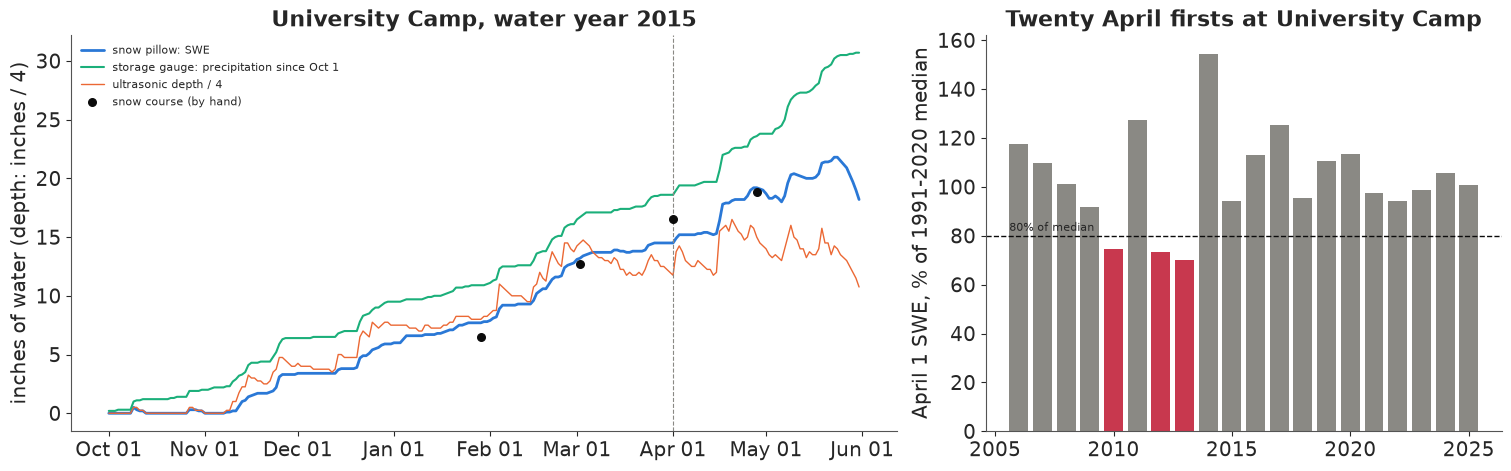

In [4]:
FEATURE = 2015


def season(y):
    return uc.loc[f"{y-1}-10-01":f"{y}-05-31"]


fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
s = season(FEATURE)
ax.plot(s.index, s.wteq, color=BLUE, lw=2, label="snow pillow: SWE")
ax.plot(s.index, s.prec, color=AQUA, lw=1.5, label="storage gauge: precipitation since Oct 1")
ax.plot(s.index, s.snwd / 4, color=ORANGE, lw=1, label="ultrasonic depth / 4")
cs = course[(course.date > f"{FEATURE-1}-10-01") & (course.date < f"{FEATURE}-06-01")]
ax.scatter(cs.date, cs.swe, color=INK, zorder=5, s=30, label="snow course (by hand)")
ax.axvline(pd.Timestamp(f"{FEATURE}-04-01"), color=MUTED, lw=0.8, ls="--")
ax.xaxis.set_major_formatter(MONTHS)
ax.set(ylabel="inches of water (depth: inches / 4)", title=f"University Camp, water year {FEATURE}")
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
colors = [RED if p < 80 else MUTED for p in 100 * apr1 / MED_APR1]
ax.bar(YEARS, 100 * apr1 / MED_APR1, color=colors)
ax.axhline(80, color=INK, lw=1, ls="--")
ax.text(2005.6, 82, "80% of median", fontsize=8)
ax.set(ylabel="April 1 SWE, % of 1991-2020 median", title="Twenty April firsts at University Camp");

The left panel shows the four windows in one season. The pillow (blue) climbs in steps, one per storm,
and starts to melt in May. The gauge (green) climbs in the same steps but faster: by April 1 it has
caught 18.6 in against the pillow's 14.5 in, because some of what it catches falls as rain in
October, some snow blows off or sublimates from the pillow, and the gauge may catch more than falls
on the pillow. The depth sensor (orange, divided by 4 to share the axis) jumps with each storm and then
sinks as the new snow settles; from March it falls while the pillow rises. The snow course (black)
reads below the pillow on February 1 and above it on April 1. Each sensor sees the same snowpack through
its own function, and the model has to learn those functions.

## 2 · The experiment, and four quick fixes

We work in weeks: 26 seven-day weeks per season, counted back from April 1, so that the season starts on
October 2 (October 3 when February has 29 days). The 18th week ends on February 4 (February 5 in leap years); in a "dead" season the pillow
reports up to then and never again. The weekly arrays hold the pillow and depth readings on the last day of each week, the
daily gauge increments and temperatures (the model turns them into weekly snowfall itself), and each
snow-course survey on the week end nearest to its date.

In [5]:
K, D = 26, 182                 # weeks per season (ending April 1) and days
LAST = 17                      # index of the last week the pillow reports (ends February 4 or 5)
SURVEYS = ["Feb 1", "Mar 1", "Apr 1"]
Y = len(YEARS)
g_d = np.zeros((D, Y)); t_d = np.zeros((D, Y))
pillow = np.full((K, Y), np.nan); depth = np.full((K, Y), np.nan); crs = np.full((K, Y), np.nan)
survey = np.zeros((K, Y), int)
week_end = np.zeros((K, Y), dtype="datetime64[D]")
dropped = []
for j, wy in enumerate(YEARS):
    a1 = pd.Timestamp(f"{wy}-04-01")
    days = pd.date_range(a1 - pd.Timedelta(days=D), a1)
    u = uc.reindex(days)
    g_d[:, j] = np.diff(u.prec.interpolate(limit_direction="both").to_numpy())
    t_d[:, j] = ((u.tavg.interpolate(limit_direction="both") - 32) / 1.8).to_numpy()[1:]
    ends = a1 - pd.to_timedelta(7 * np.arange(K - 1, -1, -1), unit="D")
    week_end[:, j] = ends.to_numpy().astype("datetime64[D]")
    pillow[:, j] = uc.wteq.reindex(ends).to_numpy()
    depth[:, j] = uc.snwd.reindex(ends).to_numpy()
    for _, r in course[(course.date > days[0]) & (course.date <= a1) & course.survey.isin(SURVEYS)].iterrows():
        if r.swe / r.depth > 0.6:
            dropped.append((r.date.date(), r.survey, r.swe, r.depth))
            continue
        k = int(np.argmin(np.abs((ends - r.date).days)))
        crs[k, j] = r.swe
        survey[k, j] = SURVEYS.index(r.survey)
truth = pillow[-1].copy()
edited = np.abs(apr1 - apr1_raw) > 0.3          # the published April 1 value is itself an NRCS estimate
ok = ~edited
print("course surveys dropped (density above 0.6, physically impossible):", dropped)
print(f"years whose published April 1 value was edited (not scored): {YEARS[edited]}")
print(f"courses used: {int(np.isfinite(crs).sum())}; weeks with no depth reading: {int(np.isnan(depth).sum())}")
print(f"last pillow week ends: {week_end[LAST, 0]} ... {week_end[LAST, -1]}")

course surveys dropped (density above 0.6, physically impossible): [(datetime.date(2012, 1, 30), 'Feb 1', 24.0, 35.0)]
years whose published April 1 value was edited (not scored): [2014]
courses used: 58; weeks with no depth reading: 8
last pillow week ends: 2006-02-04 ... 2025-02-04


One survey is dropped: the February 1 survey of 2012 records 24 in of water in 35 in of snow, a density
of 0.69, denser than any seasonal snowpack and almost certainly a recording error (the pillow held about
8 in that day, and the next survey, a month later, found 11.7 in). A survey on April 2 (2017) falls after
the decision date and is not used. That leaves 58 surveys, and eight weeks with no depth reading (the
depth sensor was out for part of 2017).

Before building anything, here are four fixes a hydrologist could make in five minutes, each using only
what is known on April 1. The crudest is to **carry forward** the last pillow reading, from February 4.
A little better is to let the **percent of median persist**: if the pillow stood at $x\%$ of its
February 4 median, assume April 1 is at $x\%$ of its April 1 median. The **neighbour ratio** multiplies
the last reading by how much the four neighbouring pillows grew between February 4 and April 1,
averaged over the neighbours, which is close to how missing SNOTEL values are estimated in practice.
And **depth times density** multiplies the April 1 depth by the density (SWE / depth) on February 4.

In [6]:
nb_names = ["Niwot", "Lake Eldora", "Wild Basin", "Bear Lake"]
Wnb = daily.pivot_table(index="date", columns="station", values="wteq")
Mnb = daily.pivot_table(index="date", columns="station", values="wteq_median")
last_day = pd.to_datetime(week_end[LAST])
a1_day = pd.to_datetime(week_end[-1])
w_last = pillow[LAST]
med_last = np.array([Mnb.loc[d, "University Camp"] for d in last_day])
base = pd.DataFrame(index=YEARS)
base["truth"] = truth
base["carry forward"] = w_last
base["% of median persists"] = w_last / med_last * MED_APR1
ratio = np.array([[Wnb.loc[a, n] / Wnb.loc[l, n] for n in nb_names] for a, l in zip(a1_day, last_day)])
base["neighbour ratio"] = w_last * ratio.mean(1)
dens_last = w_last / depth[LAST]
base["depth x Feb density"] = depth[-1] * dens_last


def score(est, sd=None):
    use = ok & np.isfinite(est)
    e = (est - truth)[use]
    out = {"years": int(use.sum()), "rmse (in)": np.sqrt(np.mean(e**2)), "bias (in)": e.mean(),
           "wrong 80% calls": int(((est < 0.8 * MED_APR1) != (truth < 0.8 * MED_APR1))[use].sum())}
    if sd is not None:
        z = ((truth - est) / sd)[use]
        out["mean sd (in)"] = sd[use].mean()
        out["mean z^2"] = np.mean(z**2)
        out["in 90% interval"] = int(np.sum(np.abs(z) < 1.645))
        out["log score"] = norm.logpdf(truth[use], est[use], sd[use]).sum()
    return out


quick = pd.DataFrame({c: score(base[c].to_numpy()) for c in base.columns[1:]}).T
print(f"scored on {ok.sum()} years; truth below 80% of median in {int((truth[ok] < 0.8 * MED_APR1).sum())}")
print(quick.round(2))

scored on 19 years; truth below 80% of median in 3
                      years  rmse (in)  bias (in)  wrong 80% calls
carry forward          19.0       5.92      -5.70             14.0
% of median persists   19.0       2.84       1.10              2.0
neighbour ratio        19.0       1.05      -0.22              1.0
depth x Feb density    18.0       2.61      -2.37              3.0


Carrying the last reading forward is useless here: on average April 1 holds 5.7 in more water than
February 4, and the method calls a drought in 17 of the 19 seasons, 14 of them wrongly. Letting the percent
of median persist is better on average (rmse 2.8 in) but makes two wrong calls, in opposite directions:
2012, a drought year that was near its median on February 4, and 2021, a normal year that was at
two-thirds of it. The neighbour ratio is the best of the four, with an error of about 1 in, and it gets
the call wrong once (2015). Depth times February density is
biased low by 2.4 in, and the left panel below shows why.

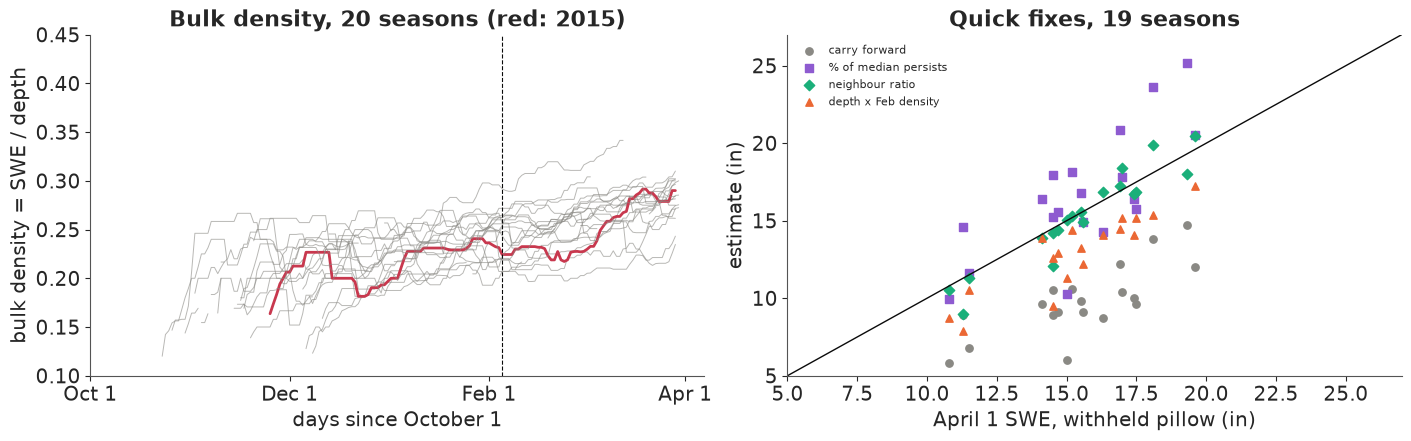

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axes[0]
for j, wy in enumerate(YEARS):
    s = season(wy).loc[:f"{wy}-04-01"]
    dd = (s.index - pd.Timestamp(f"{wy-1}-10-01")).days
    rho_obs = (s.wteq / s.snwd).where(s.snwd > 10)
    ax.plot(dd, rho_obs.rolling(7, center=True).median(), color=RED if wy == FEATURE else MUTED,
            lw=2 if wy == FEATURE else 0.7, alpha=1 if wy == FEATURE else 0.6)
ax.axvline((pd.Timestamp("2015-02-04") - pd.Timestamp("2014-10-01")).days, color=INK, ls="--", lw=0.8)
ax.set(xlabel="days since October 1", ylabel="bulk density = SWE / depth", ylim=(0.1, 0.45),
       title="Bulk density, 20 seasons (red: 2015)")
ax.set_xticks([0, 61, 122, 182], ["Oct 1", "Dec 1", "Feb 1", "Apr 1"])
ax = axes[1]
for c, col, mk in zip(base.columns[1:], [MUTED, PURPLE, AQUA, ORANGE], "osD^"):
    ax.scatter(base.truth[ok], base[c][ok], color=col, marker=mk, s=28, label=c)
lim = [5, 27]
ax.plot(lim, lim, color=INK, lw=1)
ax.set(xlabel="April 1 SWE, withheld pillow (in)", ylabel="estimate (in)", xlim=lim, ylim=lim,
       title="Quick fixes, 19 seasons")
ax.legend(fontsize=8);

The bulk density of the snowpack at University Camp starts near 0.2 in December, sits around 0.21-0.27
by early February and reaches 0.24-0.31 by April 1, rising through February and March in almost every
season. A density frozen at its
February value therefore turns April's depth into too little water. Density is not a constant to be
measured once; it is a latent quantity that changes through the season, and it varies from year to year
by a few hundredths, which on 60 in of snow is a couple of inches of water.

**Failure 1, then, is the obvious one: treating the depth sensor as a SWE sensor with a fixed
conversion.** The scatter on the right shows the four quick fixes against the withheld truth: carry-forward
(grey) far below the diagonal, persistence (purple) scattered on both sides, depth times density (orange)
consistently low, and the neighbour ratio (green) close to the line but with a few misses of 1.3-2.4 in.

## 3 · A weekly snow budget seen through four windows

### The state and how it evolves

For each season and week $k$ the hidden state has three parts: $W_k$, the snow water equivalent at the
pillow (inches of water); $F_k$, the **fresh-snow excess** - how much deeper the snow is than settled snow
of the same water content would be; and $G_k$, a **slow depth drift**, which we switch off in the first
model and come back to in part 5. Week to week,

$$W_k = \max\!\big(0,\; W_{k-1} + c_y\, s_k - m\, d_k + \eta_k\big), \qquad
\eta_k \sim N\!\big(0,\; q_0^2 + q_1^2 s_k^2\big),$$

where $s_k = \sum_{\text{days}} g_t\, \sigma\!\big((T_{\text{snow}} - T_t)/0.7\big)$ is the week's gauge
catch $g_t$, counting only the share that falls as snow at daily mean temperature $T_t$; $c_y$ is the
**catch ratio** of season $y$ (pillow gain per inch the gauge catches as snow, centred on a common value
with a small year-to-year spread); $d_k$ is the week's degree-days above 0 °C and $m$ a melt factor (Hock
2003). The noise $\eta_k$ has a floor $q_0$ and a part proportional to the week's snowfall, because a big
storm is where wind redistributes snow and the gauge is most wrong. The $\max(0,\cdot)$ is applied
smoothly (a softplus with a 0.1 in scale) and matters mainly in October and November, when early snow
comes and goes.

The fresh-snow excess grows with new snow and decays as it settles:
$F_k = \phi F_{k-1} + \kappa s_k + \nu_k$, $\nu_k \sim N(0, \sigma_F^2)$, so each inch of new water adds
$\kappa$ inches of extra depth, of which a fraction $\phi$ remains a week later. The slow drift is an
AR(1) with a coefficient near one: $G_k = \phi_G G_{k-1} + \epsilon_k$, $\epsilon_k \sim N(0, \sigma_G^2)$.
(In the code and the printed summaries $\phi_G$ and $\sigma_G$ are `phi_s` and `s_s`; $\sigma_F$, $\sigma_P$
and $\sigma_C$ below are `s_f`, `s_p` and `s_c`.)

### The four windows

$$\begin{aligned}
\text{pillow:}\quad & y^P_k = W_k + e^P_k, & e^P_k &\sim N(0, \sigma_P^2) \\
\text{depth:}\quad & y^D_k = W_k/\rho_{k,y} + F_k + G_k + e^D_k, & e^D_k &\sim N(0, 0.5^2) \\
\text{course:}\quad & y^C_k = \lambda_{\text{survey}} W_k + e^C_k, & e^C_k &\sim N(0, \sigma_C^2) \\
\text{gauge:}\quad & \text{drives } s_k \text{ in the budget}
\end{aligned}$$

The settled-snow density is $\log \rho_{k,y} = a_y + b\, u_k$, a level $a_y$ for each season (pooled across
seasons) and a common rise $b$ per unit of $u_k$, which runs from 0 on February 4 to 1 on April 1. The
depth sensor's own noise is fixed at 0.5 in, about its specified accuracy. The course has its own ratio
$\lambda$ to the pillow for each survey, because it is a different transect of snow surveyed at a
different time of year.

Every observation is linear in the state once the parameters are fixed (the density enters as the known
coefficient $1/\rho_{k,y}$), so the Kalman filter computes the likelihood of all the readings with the
states integrated out exactly - apart from the smooth floor at zero, which we treat as part of the
prediction step, taking its slope as 1 when the variance is carried forward (exact away from zero, and
the floor only bites in the thin snow of autumn). NUTS then samples the 60 parameter values while the filter handles the
$3 \times 26 \times 20 = 1{,}560$ states. A missing reading simply skips its update, which is how a dead
pillow enters the model: as missing data.

The gauge is not an observation of the state but an input. That is a modelling choice: it treats the
gauge as noise-free and puts all its error into $\eta_k$ and the catch ratio, which is reasonable for a
storage gauge read to 0.1 in.

### One filter, two backends

The filter below is written once with plain arithmetic, elementwise over seasons, so that the same
function runs inside a PyTensor `scan` (for NUTS) and in a NumPy loop over posterior draws (for nowcasts
and checks). The 3 × 3 covariance is kept as a dictionary of its six distinct entries; every update reads
one scalar sensor.

In [8]:
gpos = np.clip(g_d, 0.0, None)                                 # daily gauge catch (in), noise below 0 removed
dd_w = np.clip(t_d, 0.0, None).reshape(K, 7, Y).sum(1)          # weekly degree-days above 0 C
s_w = np.broadcast_to(((np.arange(K) - LAST) / (K - 1 - LAST))[:, None], (K, Y))   # 0 on Feb 4, 1 on Apr 1
NP_OPS = SimpleNamespace(log=np.log, softplus=lambda z: np.logaddexp(0.0, z))
PT_OPS = SimpleNamespace(log=pt.log, softplus=pt.softplus)
KEYS = [(0, 0), (0, 1), (0, 2), (1, 1), (1, 2), (2, 2)]        # upper triangle of the 3 x 3 covariance
S_H = 0.5                                                      # depth sensor noise (in), from its specification


def kf_update(x, P, h, y, r, m, ops):
    """Kalman update with one scalar reading y = h.x + noise(r), applied where m == 1.
    x: list of state means, P: dict of covariances, h: coefficients (None = 0). Elementwise over years."""
    cov = lambda i, j: P[(min(i, j), max(i, j))]
    Ph = [sum(cov(i, j) * h[j] for j in range(3) if h[j] is not None) for i in range(3)]
    S = sum(h[i] * Ph[i] for i in range(3) if h[i] is not None) + r
    v = y - sum(h[i] * x[i] for i in range(3) if h[i] is not None)
    g = m / S
    x = [x[i] + g * v * Ph[i] for i in range(3)]
    P = {(i, j): P[(i, j)] - g * Ph[i] * Ph[j] for (i, j) in P}
    return x, P, m * -0.5 * (ops.log(2 * np.pi * S) + v**2 / S), (v, S)


def kf_week(x, P, u, prm, obs, ops, gate=None):
    """One week of the snow budget: predict, then read the pillow, the depth sensor and the course.
    With `gate`, a pillow reading more than `gate` predictive sds from its prediction is ignored."""
    acc, melt_w, qW, snow, rho, lam = u
    phi, kappa, s_f, s_p, s_c, phi_s, s_s = prm
    yP, mP, yD, mD, yC, mC = obs
    f = [1.0, phi, phi_s]
    x = [0.1 * ops.softplus((x[0] + acc - melt_w) / 0.1),       # SWE cannot go below zero
         phi * x[1] + kappa * snow,                             # new snow is fluffy, then settles
         phi_s * x[2]]                                          # slow depth drift
    q = [qW, s_f**2, s_s**2]
    P = {(i, j): P[(i, j)] * f[i] * f[j] + (q[i] if i == j else 0.0) for (i, j) in KEYS}
    if gate is not None:
        mP = mP * (abs(yP - x[0]) < gate * (P[(0, 0)] + s_p**2) ** 0.5)
    x, P, l1, i1 = kf_update(x, P, [1.0, None, None], yP, s_p**2, mP, ops)
    x, P, l2, i2 = kf_update(x, P, [1.0 / rho, 1.0, 1.0], yD, S_H**2, mD, ops)
    x, P, l3, i3 = kf_update(x, P, [lam, None, None], yC, s_c**2, mC, ops)
    return x, P, l1 + l2 + l3, (i1, i2, i3, mP)


def pillow_until_feb(dead_years):
    """Pillow readings with everything after the first week of February removed in `dead_years`."""
    p = pillow.copy()
    p[LAST + 1:, dead_years] = np.nan
    return np.nan_to_num(p), np.isfinite(p).astype(float)


obs0 = dict(yD=np.nan_to_num(depth), mD=np.isfinite(depth).astype(float),
            yC=np.nan_to_num(crs), mC=np.isfinite(crs).astype(float))

### The PyMC model

The readings and their masks are `pm.Data`, and so is a switch `slow_on` that multiplies the slow drift's
scale. That lets one compiled model be refitted with different seasons dead, different sensors removed
and the drift on or off. The priors are weakly informative and on physical scales: the catch ratio is
centred on 1 with a factor of about 1.35 either way; the settled density on 0.27; the density's rise
on 10% (±10%) between February 4 and April 1; the fresh-snow decay $\phi \sim \text{Beta}(2, 2)$; the
course ratio on 1 (±20%), with each survey allowed another ±10%; the slow drift's $\phi_G \sim
\text{Beta}(20, 1)$, a memory of weeks to months.

In [9]:
yP_init, mP_init = pillow_until_feb(np.arange(Y) % 2 == 0)
with pm.Model(coords={"year": YEARS, "survey": SURVEYS, "week": np.arange(K)}) as model:
    yP = pm.Data("yP", yP_init); mP = pm.Data("mP", mP_init)
    yD = pm.Data("yD", obs0["yD"]); mD = pm.Data("mD", obs0["mD"])
    yC = pm.Data("yC", obs0["yC"]); mC = pm.Data("mC", obs0["mC"])
    slow_on = pm.Data("slow_on", 1.0)
    # accumulation: pillow gain per inch the gauge catches, one ratio per year around a common one
    mu_c = pm.Normal("mu_c", 0.0, 0.3)
    tau_c = pm.HalfNormal("tau_c", 0.2)
    c = pm.Deterministic("c", pt.exp(mu_c + tau_c * pm.Normal("z_c", 0, 1, dims="year")), dims="year")
    t_snow = pm.Normal("t_snow", 1.0, 1.0)                      # deg C at which half the precipitation is snow
    melt = pm.HalfNormal("melt", 0.05)                         # in per degree-day
    q0 = pm.HalfNormal("q0", 0.3)                              # weekly budget error (in)
    q1 = pm.HalfNormal("q1", 0.3)                              # ... growing with the week's snowfall
    s_p = pm.HalfNormal("s_p", 0.3)                            # pillow noise (in)
    # density of the settled pack: a level per year and a common rise through the season
    mu_a = pm.Normal("mu_a", np.log(0.27), 0.2)
    tau_a = pm.HalfNormal("tau_a", 0.15)
    log_rho0 = pm.Deterministic("log_rho0", mu_a + tau_a * pm.Normal("z_a", 0, 1, dims="year"), dims="year")
    b_rho = pm.Normal("b_rho", 0.1, 0.1)
    # depth anomalies: fresh snow (fast) and a slow drift
    phi = pm.Beta("phi", 2, 2)
    kappa = pm.HalfNormal("kappa", 3.0)                        # extra inches of depth per inch of new snow
    s_f = pm.HalfNormal("s_f", 2.0)
    phi_s = pm.Beta("phi_s", 20, 1)
    s_s = pm.HalfNormal("s_s", 1.0)
    # snow course: its own ratio to the pillow for each survey
    lam = pm.Deterministic("lam", pt.exp(pm.Normal("lam0", 0.0, 0.2)
                                         + pm.Normal("dlam", 0.0, 0.1, dims="survey")), dims="survey")
    s_c = pm.HalfNormal("s_c", 1.0)

    snow_w = (gpos * pm.math.sigmoid((t_snow - t_d) / 0.7)).reshape((K, 7, Y)).sum(1)
    u_seq = [c[None, :] * snow_w, melt * dd_w, q0**2 + (q1 * snow_w) ** 2, snow_w,
             pt.exp(log_rho0[None, :] + b_rho * s_w), lam[survey]]
    prm = [phi, kappa, s_f, s_p, s_c, phi_s, s_s * slow_on]

    def step(*args):
        u, obs, carry, prm_ = args[:6], args[6:12], args[12:21], args[21:]
        x, P = list(carry[:3]), dict(zip(KEYS, carry[3:]))
        x, P, ll, _ = kf_week(x, P, u, prm_, obs, PT_OPS)
        return [*x, *[P[k] for k in KEYS], ll]

    zero = pt.zeros(Y)
    init = [zero] * 3 + [zero + (0.05 if k == (0, 0) else 0.0) for k in KEYS]
    outs = pytensor.scan(step, sequences=u_seq + [yP, mP, yD, mD, yC, mC], outputs_info=init + [None],
                         non_sequences=prm, return_updates=False)
    pm.Potential("loglik", outs[-1].sum())
    pm.Deterministic("swe_apr1", outs[0][-1], dims="year")
    pm.Deterministic("sd_apr1", pt.sqrt(outs[3][-1]), dims="year")
print(f"{len(model.free_RVs)} free variables, {sum(np.size(v) for v in model.initial_point().values())} numbers "
      f"for NUTS; the {3 * K * Y} weekly states are integrated out by the filter")

20 free variables, 60 numbers for NUTS; the 1560 weekly states are integrated out by the filter


Two details matter for PyTensor. Model variables used inside the `scan` step must arrive as
`non_sequences` (the step function receives them as arguments rather than closing over them). And the
last two deterministics are the filter's answer for April 1: in the last week the filtered mean and sd of
$W$ given every reading up to April 1, which is exactly the nowcast a manager would have that day. Its
predictive distribution averages $N(\text{mean}, \text{sd}^2)$ over posterior draws.

### Prior predictive check

A `pm.Potential` has no generative story PyMC can sample, so we draw parameters from the prior and push
them through the budget in NumPy, using the real weather of 2015.

In [10]:
PARAMS = ["c", "t_snow", "melt", "q0", "q1", "s_p", "log_rho0", "b_rho", "phi", "kappa", "s_f", "phi_s", "s_s",
          "lam", "s_c"]
with model:
    prior = pm.sample_prior_predictive(draws=400, var_names=PARAMS, random_seed=RANDOM_SEED)


def draws_of(tree, n=None, group="posterior"):
    """Flatten (chain, draw) into one axis; scalars become (n, 1) so they broadcast over years."""
    ds = tree[group]
    out = {}
    for v in PARAMS:
        a = ds[v].values
        a = a.reshape(-1, *a.shape[2:])
        out[v] = a[:, None] if a.ndim == 1 else a
    if n is not None:
        idx = np.random.default_rng(1).choice(len(out["t_snow"]), n, replace=False)
        out = {k: v[idx] for k, v in out.items()}
    return out


def weekly_inputs(p):
    snow = gpos[None] / (1 + np.exp(-(p["t_snow"][:, None, :] - t_d[None]) / 0.7))   # (n, D, Y)
    snow = snow.reshape(-1, K, 7, Y).sum(2)                                            # (n, K, Y)
    rho = np.exp(p["log_rho0"][:, None, :] + p["b_rho"][:, None, :] * s_w[None])
    lam_t = p["lam"][:, survey]
    return snow, rho, lam_t


def simulate(p, rng):
    """Forward-simulate seasons from parameter draws p (no data): weekly SWE and depth readings."""
    snow, rho, lam_t = weekly_inputs(p)
    n = snow.shape[0]
    W = np.zeros((n, Y)); F = np.zeros((n, Y)); S = np.zeros((n, Y))
    sw, dp = np.zeros((n, K, Y)), np.zeros((n, K, Y))
    for k in range(K):
        qW = np.sqrt(p["q0"] ** 2 + (p["q1"] * snow[:, k]) ** 2)
        dW = p["c"] * snow[:, k] - p["melt"] * dd_w[k] + qW * rng.normal(size=(n, Y))
        W = 0.1 * np.logaddexp(0, (W + dW) / 0.1)
        F = p["phi"] * F + p["kappa"] * snow[:, k] + p["s_f"] * rng.normal(size=(n, Y))
        S = p["phi_s"] * S + p["s_s"] * rng.normal(size=(n, Y))
        sw[:, k], dp[:, k] = W, W / rho[:, k] + F + S + S_H * rng.normal(size=(n, Y))
    return sw, dp


pri = draws_of(prior, group="prior")
sw_pr, dp_pr = simulate(pri, np.random.default_rng(2))
q = np.quantile(sw_pr[:, -1, :], [0.05, 0.5, 0.95], axis=0)
print("prior predictive April 1 SWE, median of years (in): 5% {:.1f}, 50% {:.1f}, 95% {:.1f}".format(
    *np.median(q, axis=1)))
print(f"share of prior draws with April 1 SWE above 40 in: {np.mean(sw_pr[:, -1] > 40):.3f}; "
      f"with depth above 200 in: {np.mean(dp_pr[:, -1] > 200):.3f}")

prior predictive April 1 SWE, median of years (in): 5% 7.8, 50% 16.5, 95% 32.1
share of prior draws with April 1 SWE above 40 in: 0.022; with depth above 200 in: 0.011


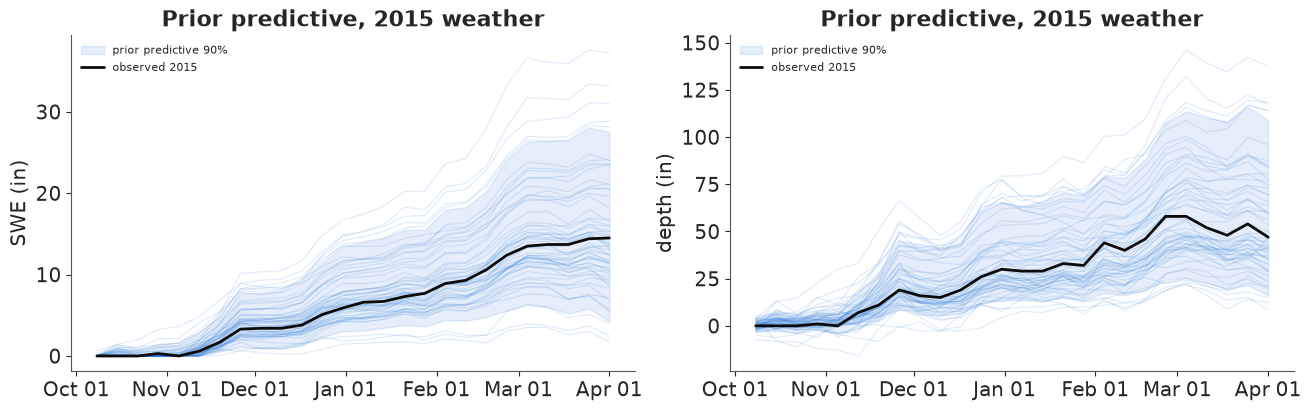

In [11]:
jf = list(YEARS).index(FEATURE)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
wk = pd.to_datetime(week_end[:, jf])
for ax, sim, obs, lab in ((axes[0], sw_pr, pillow, "SWE (in)"), (axes[1], dp_pr, depth, "depth (in)")):
    for i in range(60):
        ax.plot(wk, sim[i, :, jf], color=BLUE, alpha=0.15, lw=0.8)
    qq = np.quantile(sim[:, :, jf], [0.05, 0.95], axis=0)
    ax.fill_between(wk, qq[0], qq[1], color=BLUE, alpha=0.12, label="prior predictive 90%")
    ax.plot(wk, obs[:, jf], color=INK, lw=2, label=f"observed {FEATURE}")
    ax.xaxis.set_major_formatter(MONTHS)
    ax.set(ylabel=lab, title=f"Prior predictive, {FEATURE} weather")
    ax.legend(fontsize=8)

Driven by the real 2015 storms, the prior puts April 1 SWE between about 8 and 32 in (90%, median of the
twenty seasons' intervals) and, in 2015, depth on April 1 between about 20 and 110 in. The observed season
sits inside both bands, near their middle. Only 2% of draws give more than 40 in of water on April 1 and 1% give more than 200 in of depth - the prior allows a wide range of
snowpacks, and almost none that are physically absurd.

## 4 · Fitting the budget, and the check that matters

**The backtest.** We split the twenty seasons into two halves, alternate years. In fold 0 the pillow dies
on February 4 in the even-indexed seasons (2006, 2008, ...) and works all winter in the others; in fold 1
the halves swap. Each fold is one fit, and each dead season is predicted by the fit in which it was dead,
so no season's withheld readings ever inform its own forecast. The working seasons teach the model the
catch ratio, the density curve and the course ratios, as the station's own history would in a real
outage.

We compile once with nutpie and swap the data with `with_data`; each refit then costs only sampling time.
nutpie's default warm-up is 400 steps; we keep it, with 1,000 draws per chain.

In [12]:
t0 = time.time()
compiled = nutpie.compile_pymc_model(model)
print(f"compiled in {time.time() - t0:.0f} s")
DIAG = ["mu_c", "tau_c", "t_snow", "melt", "q0", "q1", "s_p", "mu_a", "tau_a", "b_rho", "phi", "kappa", "s_f",
        "lam", "s_c", "phi_s", "s_s"]


def fit_two_folds(label, slow=1.0, mD=None, mC=None, draws=1000, tune=400, keep=False):
    """Kill the pillow after February 4 in half the years, fit, predict those years; then swap halves."""
    mean, sd, fits = np.zeros(Y), np.zeros(Y), []
    for fold in (0, 1):
        dead = np.arange(Y) % 2 == fold
        yP_, mP_ = pillow_until_feb(dead)
        t0 = time.time()
        tr = nutpie.sample(compiled.with_data(yP=yP_, mP=mP_, slow_on=slow,
                                              mD=obs0["mD"] if mD is None else mD,
                                              mC=obs0["mC"] if mC is None else mC),
                           draws=draws, tune=tune, chains=4, seed=RANDOM_SEED + fold, progress_bar=False)
        rhat = max(float(az.rhat(tr.posterior[v]).max()) for v in DIAG)
        ess = min(float(az.ess(tr.posterior[v]).min()) for v in DIAG)
        print(f"{label:>16s} fold {fold}: {time.time() - t0:4.0f} s, divergences "
              f"{int(tr.sample_stats['diverging'].sum())}, max r_hat {rhat:.3f}, min bulk ESS {ess:.0f}")
        w = tr.posterior["swe_apr1"].values.reshape(-1, Y)
        v = tr.posterior["sd_apr1"].values.reshape(-1, Y) ** 2
        mean[dead] = w.mean(0)[dead]
        sd[dead] = np.sqrt(v.mean(0) + w.var(0))[dead]
        if keep:
            fits.append(tr)
    return mean, sd, fits


naive_mean, naive_sd, naive_fits = fit_two_folds("fast anomaly only", slow=0.0, keep=True)

compiled in 29 s


fast anomaly only fold 0:   14 s, divergences 0, max r_hat 1.009, min bulk ESS 306


fast anomaly only fold 1:   14 s, divergences 0, max r_hat 1.004, min bulk ESS 408


The first model has the slow drift switched off (`slow_on = 0`): the depth sensor's departures from
$W/\rho$ are the fresh-snow excess plus white noise. Both folds sample in under half a minute each, with no
divergences, $\hat r \le 1.02$ and a smallest bulk ESS of several hundred (the density level $\mu_a$,
which trades off against the per-season levels). The parameters of fold 0:

In [13]:
print(az.summary(naive_fits[0], var_names=DIAG, round_to=3).iloc[:, [0, 1, 2, 3, 4, 6]])

             mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
mu_c       -0.137  0.016    -0.162    -0.113  3587.576  1.001
tau_c       0.045  0.018     0.015     0.075   893.489  1.002
t_snow      0.401  0.184     0.126     0.707  5120.012  1.002
melt        0.007  0.001     0.006     0.008  6680.339  1.001
q0          0.098  0.013     0.079     0.119  1788.321  1.000
q1          0.123  0.015     0.100     0.147  3569.153  1.000
s_p         0.051  0.012     0.030     0.068  1621.361  1.003
mu_a       -1.331  0.024    -1.369    -1.291   305.681  1.009
tau_a       0.097  0.017     0.074     0.127   685.813  1.003
b_rho       0.104  0.007     0.093     0.115  4145.301  1.001
phi         0.284  0.038     0.222     0.344  4008.524  1.000
kappa       2.764  0.137     2.543     2.977  4236.518  1.001
s_f         1.611  0.060     1.516     1.709  5602.129  1.002
lam[Feb 1]  1.128  0.028     1.083     1.171  4604.812  1.000
lam[Mar 1]  1.141  0.022     1.106     1.176  4347.951  1.000
lam[Apr 

They read as physics. The **catch ratio** is $e^{-0.137} \approx 0.87$: the pillow gains 0.87 in of water
for every inch the gauge catches as snow, with a year-to-year spread of about 4%. The snow-rain
threshold sits at 0.4 °C. The melt factor is 0.007 in per degree-day, tiny, because before April the
pack is cold and warm days are few. The weekly budget error has a floor of 0.1 in and grows by 0.12 in per inch of the
week's snowfall (the two added in quadrature).
The **settled density** is $e^{-1.33} \approx 0.26$ on February 4, varies by about 10% between seasons and
rises by 11% ($e^{0.104}$) by April 1. **New snow** adds 2.8 in of extra depth per inch of water and
settles fast: only 28% of the excess is left after a week. The **snow course** reads 11-14% more water
than the pillow, with an error of 1.2 in relative to it. The pillow's own noise is 0.05 in. The slow drift
parameters ($\phi_G$, $\sigma_G$) show their priors, since the switch is off.

### A unit check, and two kinds of predictive check

The NumPy copy of the filter must agree with the PyTensor one. We evaluate both at one posterior draw.
Then we run the NumPy filter over 200 posterior draws per fold and collect the **innovations**: each
reading minus its prediction from everything before it, divided by the predicted sd. If the model is
right, these are independent standard normals - the check E13 called the one that matters. We standardise
each innovation by the predictive distribution that mixes over the draws (its mean over draws, divided by
the square root of the mean predicted variance plus the variance of the predictions), and we look at the
depth sensor and the course in the dead weeks after February 4, where they carry the load. And we score the forecast we
actually care about, eight weeks ahead: April 1 in each dead season, by the share of truths inside the
90% interval, the mean squared standardised error ($z^2$, 1 if calibrated) and the log score (sum of log
predictive densities, higher is better).

In [14]:
def run_filter(p, yP_, mP_, mD_=obs0["mD"], mC_=obs0["mC"], gate=None):
    """The same filter in NumPy over posterior draws: weekly filtered SWE mean/var, the standardised
    innovations of each sensor, the log-likelihood, and which pillow readings were used."""
    snow, rho, lam_t = weekly_inputs(p)
    n = snow.shape[0]
    x = [np.zeros((n, Y))] * 3
    P = {k: np.full((n, Y), 0.05 if k == (0, 0) else 0.0) for k in KEYS}
    prm = [p["phi"], p["kappa"], p["s_f"], p["s_p"], p["s_c"], p["phi_s"], p["s_s"]]
    m_, v_, z_, ll = np.zeros((n, K, Y)), np.zeros((n, K, Y)), np.full((3, n, K, Y), np.nan), 0.0
    vs_, Ss_ = np.full((3, n, K, Y), np.nan), np.full((3, n, K, Y), np.nan)
    used = np.zeros((n, K, Y))
    for k in range(K):
        u = [p["c"] * snow[:, k], p["melt"] * dd_w[k], p["q0"] ** 2 + (p["q1"] * snow[:, k]) ** 2, snow[:, k],
             rho[:, k], lam_t[:, k]]
        ob = [yP_[k], mP_[k], obs0["yD"][k], mD_[k], obs0["yC"][k], mC_[k]]
        x, P, l, inn = kf_week(x, P, u, prm, ob, NP_OPS, gate)
        ll = ll + l.sum(axis=1)
        m_[:, k], v_[:, k], used[:, k] = x[0], P[(0, 0)], inn[3]
        for i, (vv, SS) in enumerate(inn[:3]):
            z_[i, :, k] = np.where(ob[2 * i + 1] > 0, vv / np.sqrt(SS), np.nan)
            vs_[i, :, k], Ss_[i, :, k] = np.where(ob[2 * i + 1] > 0, vv, np.nan), SS
    run_filter.raw = (vs_, Ss_)                  # raw innovations and their variances, per draw
    return m_, v_, z_, ll, used


def pooled_draws(fits, slow=1.0, n=300):
    """Draws from each fold, with the slow drift switched off when the fit had it off."""
    ps = []
    for tr in fits:
        p = draws_of(tr, n)
        p["s_s"] = p["s_s"] * slow
        ps.append(p)
    return ps


def lag_corr(z, lag):
    a, b = z[:, :-lag], z[:, lag:]
    keep = np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(a[keep], b[keep])[0, 1]


# a unit check: the NumPy filter and the PyTensor model give the same log-likelihood at a posterior draw
tr0 = naive_fits[0]
point = {}
for rv in model.free_RVs:
    val, tf = tr0.posterior[rv.name].values[0, 0], model.rvs_to_transforms.get(rv)
    point[model.rvs_to_values[rv].name] = val if tf is None else tf.forward(pt.as_tensor(val)).eval()
with model:
    pm.set_data({"slow_on": 0.0})
    ll_pytensor = model.compile_fn(model.replace_rvs_by_values([model.potentials[0]])[0])(point)
    pm.set_data({"slow_on": 1.0})
p1 = {k: v[:1] for k, v in draws_of(tr0).items()}
p1["s_s"] = 0 * p1["s_s"]
ll_numpy = run_filter(p1, *pillow_until_feb(np.arange(Y) % 2 == 0))[3][0]
print(f"log-likelihood at one draw: PyTensor {float(ll_pytensor):.4f}, NumPy {ll_numpy:.4f}")


def dead_week_innovations(fits, slow):
    """Depth and course innovations in the weeks after the pillow died (dead years only), standardised by
    the predictive distribution that mixes over posterior draws: mean of the innovations over draws,
    divided by sqrt(mean of their predicted variances + variance of the innovations across draws)."""
    zd, zc = [], []
    for fold, tr in enumerate(fits):
        dead = np.arange(Y) % 2 == fold
        run_filter(pooled_draws([tr], slow=slow, n=200)[0], *pillow_until_feb(dead))
        v, S = run_filter.raw
        seen = np.isfinite(v[:, 0])                                   # a reading is seen in all draws or none
        v = np.nan_to_num(v)
        z = np.where(seen, v.mean(axis=1) / np.sqrt(S.mean(axis=1) + v.var(axis=1)), np.nan)  # (sensor, week, year)
        zd.append(z[1][LAST + 1:][:, dead])                                       # (dead weeks, dead years)
        zc.append(z[2][LAST + 1:][:, dead])
    return np.concatenate(zd, axis=1), np.concatenate(zc, axis=1)


def report(label, zd, zc, mean, sd):
    sc = score(mean, sd)
    print(f"{label}: one week ahead, depth z sd {np.nanstd(zd):.2f}, lag-1 autocorrelation "
          f"{lag_corr(zd.T, 1):+.2f}; course z sd {np.nanstd(zc):.2f} (n = {np.isfinite(zc).sum()})")
    print(f"{label}: eight weeks ahead (April 1), rmse {sc['rmse (in)']:.2f} in, "
          f"mean sd {sc['mean sd (in)']:.2f} in, mean z^2 {sc['mean z^2']:.2f}, {sc['in 90% interval']} of {sc['years']} inside the 90% interval, "
          f"log score {sc['log score']:.1f}")


zd_naive, zc_naive = dead_week_innovations(naive_fits, slow=0.0)
report("fast anomaly only", zd_naive, zc_naive, naive_mean, naive_sd)

log-likelihood at one draw: PyTensor -914.4967, NumPy -914.4967
fast anomaly only: one week ahead, depth z sd 1.07, lag-1 autocorrelation +0.09; course z sd 0.95 (n = 39)
fast anomaly only: eight weeks ahead (April 1), rmse 0.46 in, mean sd 0.37 in, mean z^2 1.54, 13 of 19 inside the 90% interval, log score -13.1


The two implementations agree to four decimals, so everything computed in NumPy below is the model that
NUTS fitted.

One week ahead, the first model looks healthy. In the weeks after the pillow died, the depth sensor's
standardised innovations have an sd of 1.07 (1 if calibrated) and almost no autocorrelation from one week
to the next; the 39 course surveys of the dead weeks have an sd of 0.95. Eight weeks ahead it is a different story. The April 1
nowcasts are good - an rmse of under half an inch, against 1 in for the neighbour ratio - but their
stated sd (0.37 in) is too small for their errors: the mean $z^2$ is about 1.55 and only 13 of the 19 truths fall
inside the 90% intervals, where we would expect about 17.

**Failure 2: checks one week ahead cannot see an error that only matters when it is added up over
eight weeks.** The filter treats each week's depth reading as a fresh, independent look at the
snowpack, up to the short-lived fresh-snow excess. If the depth sensor is off in a way that persists -
the density of this year's pack drifting away from the smooth curve, snow settling unevenly around the
sensor's footprint - then eight weeks of depth readings repeat the same error eight times, and the model
counts them as eight independent pieces of evidence. Each week's surprise is small and looks like noise;
the cumulative overconfidence only shows at the horizon of the decision.

## 5 · The fix: let the depth sensor's error drift

The fix is the third state, $G_k$: a slow AR(1) drift in depth that the pillow can pin down while it
works and that, after the pillow dies, the depth sensor cannot distinguish from a change in snow water.
It costs two parameters and no new compilation - we flip `slow_on` to 1.

In [15]:
full_mean, full_sd, full_fits = fit_two_folds("with slow drift", slow=1.0, keep=True)
print(az.summary(full_fits[0], var_names=DIAG, round_to=3).iloc[:, [0, 1, 2, 3, 4, 6]])

 with slow drift fold 0:   13 s, divergences 0, max r_hat 1.004, min bulk ESS 1046


 with slow drift fold 1:   13 s, divergences 0, max r_hat 1.005, min bulk ESS 723
             mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
mu_c       -0.135  0.016    -0.160    -0.111  3571.958  1.001
tau_c       0.041  0.019     0.011     0.072  1067.797  1.000
t_snow      0.439  0.191     0.148     0.759  5565.253  1.001
melt        0.007  0.001     0.006     0.008  5543.003  1.000
q0          0.096  0.012     0.077     0.116  1966.219  1.002
q1          0.127  0.015     0.103     0.151  3554.962  1.003
s_p         0.052  0.011     0.034     0.067  1764.040  1.003
mu_a       -1.338  0.022    -1.374    -1.303  1277.819  1.004
tau_a       0.082  0.019     0.056     0.115  1046.153  1.003
b_rho       0.118  0.010     0.103     0.133  3923.645  1.000
phi         0.172  0.045     0.101     0.243  3545.403  1.001
kappa       2.715  0.134     2.503     2.934  4432.408  1.000
s_f         1.351  0.087     1.211     1.488  3052.852  1.000
lam[Feb 1]  1.128  0.028     1.082     1.172  4648

Sampling is as clean as before: no divergences, $\hat r \le 1.02$. The data want the drift: its weekly sd
is 0.67 in (89% interval about 0.48-0.86), well away from zero against a HalfNormal(1) prior. Its persistence,
$\phi_G = 0.94$ (half-life about ten weeks), is another matter: the Beta(20, 1) prior has mean 0.95 and sd
0.045, and the posterior (0.94 ± 0.044) has barely moved from it, so that number is our assumption of a
slow drift, not something the data taught us. Together they let the drift wander by about 2 in of depth.
Part of what the first model called fresh-snow noise moves into it: $\sigma_F$ drops from 1.6 to 1.35 in
and the fresh-snow persistence $\phi$ from 0.28 to 0.17. The density's rise steepens a little ($b$ from
0.104 to 0.118, 11% to 13% by April 1); the other parameters hardly move.

In [16]:
zd_full, zc_full = dead_week_innovations(full_fits, slow=1.0)
report("with slow drift", zd_full, zc_full, full_mean, full_sd)

with slow drift: one week ahead, depth z sd 1.10, lag-1 autocorrelation +0.06; course z sd 0.95 (n = 39)
with slow drift: eight weeks ahead (April 1), rmse 0.44 in, mean sd 0.40 in, mean z^2 1.19, 16 of 19 inside the 90% interval, log score -11.1


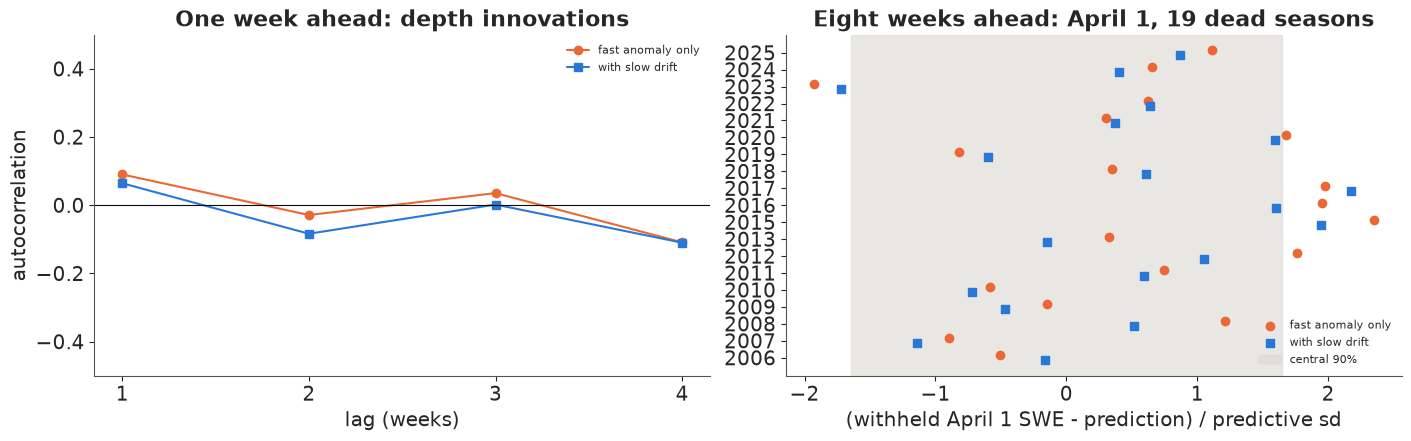

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axes[0]
lags = np.arange(1, 5)
ax.plot(lags, [lag_corr(zd_naive.T, L) for L in lags], "o-", color=ORANGE, label="fast anomaly only")
ax.plot(lags, [lag_corr(zd_full.T, L) for L in lags], "s-", color=BLUE, label="with slow drift")
ax.axhline(0, color=INK, lw=0.8)
ax.set(xlabel="lag (weeks)", ylabel="autocorrelation", ylim=(-0.5, 0.5), xticks=lags,
       title="One week ahead: depth innovations")
ax.legend(fontsize=8)
ax = axes[1]
zn, zf = ((truth - naive_mean) / naive_sd)[ok], ((truth - full_mean) / full_sd)[ok]
yy = np.arange(ok.sum())
ax.scatter(zn, yy + 0.15, color=ORANGE, marker="o", label="fast anomaly only")
ax.scatter(zf, yy - 0.15, color=BLUE, marker="s", label="with slow drift")
ax.axvspan(-1.645, 1.645, color=LIGHT, alpha=0.6, zorder=0, label="central 90%")
ax.set_yticks(yy, YEARS[ok])
ax.set(xlabel="(withheld April 1 SWE - prediction) / predictive sd",
       title=f"Eight weeks ahead: April 1, {ok.sum()} dead seasons")
ax.legend(fontsize=8, loc="lower right");

The left panel is the check that sees nothing: the depth innovations of both models are close to
uncorrelated at every lag. The right panel is the check that matters. With the drift, the April 1 errors
are about the size the model says they are: the mean $z^2$ falls from about 1.55 to 1.2, 16 of the 19 truths
are inside the 90% intervals instead of 13, and the log score improves by 2 nats. A caution about that
improvement: we chose the fix after seeing this backtest overconfident, and we score it on the same 19
seasons, so 16 of 19 is a check that the fix does what it was built to do, not an independent test of it. The intervals widen only
a little (mean sd 0.40 in against 0.37 in), and the rmse hardly changes (0.44 in against 0.46 in): the fix
is about honesty, not accuracy. Nineteen seasons are few, and three misses in nineteen is still within
reach of a calibrated 90% interval. Most errors on both models are positive (orange and blue points right
of zero): the model tends to under-predict April 1 by about 0.15 in, a bias we do not chase
further.

## 6 · What each window buys

Since the sensors enter only through masks, we can refit with any of them removed - the depth sensor's
mask or the course's set to zero in every week of every season, so the model never sees that sensor at
all - without recompiling. These refits use 400 draws per
chain after 300 warm-up steps, enough for means and sds.

In [18]:
abl = {"all four": (full_mean, full_sd)}
abl["gauge only"] = fit_two_folds("gauge only", mD=0 * obs0["mD"], mC=0 * obs0["mC"], draws=400, tune=300)[:2]
abl["gauge + depth"] = fit_two_folds("gauge + depth", mC=0 * obs0["mC"], draws=400, tune=300)[:2]
abl["gauge + course"] = fit_two_folds("gauge + course", mD=0 * obs0["mD"], draws=400, tune=300)[:2]
table = pd.DataFrame({k: score(*v) for k, v in abl.items()}).T
print(table.drop(columns=["years", "wrong 80% calls"]).round(2))

      gauge only fold 0:    6 s, divergences 0, max r_hat 1.010, min bulk ESS 314


      gauge only fold 1:    6 s, divergences 0, max r_hat 1.009, min bulk ESS 443


   gauge + depth fold 0:    6 s, divergences 0, max r_hat 1.013, min bulk ESS 301


   gauge + depth fold 1:    6 s, divergences 0, max r_hat 1.017, min bulk ESS 254


  gauge + course fold 0:    6 s, divergences 0, max r_hat 1.013, min bulk ESS 374


  gauge + course fold 1:   12 s, divergences 0, max r_hat 1.005, min bulk ESS 365
                rmse (in)  bias (in)  mean sd (in)  mean z^2  in 90% interval  log score
all four             0.44      -0.16          0.40      1.19             16.0     -11.12
gauge only           0.48      -0.20          0.52      0.90             18.0     -13.18
gauge + depth        0.43      -0.15          0.43      0.97             17.0     -10.57
gauge + course       0.48      -0.21          0.46      1.05             17.0     -12.63


This is not the result we set out to show, and it deserves to be stated plainly: **at University Camp the
precipitation gauge does almost all of the work.** Driven by the gauge alone - with the catch ratio,
melt and noise learned from the pillow's working weeks and seasons - the budget predicts April 1 with an
rmse of 0.48 in, and its intervals are, if anything, a little wide (18 of 19 inside). Adding the depth
sensor trims the rmse to 0.43 in and the sd from 0.52 to 0.43 in, and gives the best log score. Adding the
course on top of the gauge changes the rmse by nothing and narrows the intervals a little; adding it on
top of gauge and depth leaves the rmse at 0.44 in and makes the log score slightly worse.

The course is accurate about the course, not about the pillow. Its error relative to the pillow is about
1.2 in, two to three times the uncertainty that the gauge-driven budget already has on April 1, so the filter
gives it little weight. A manual survey is invaluable for checking the network and for the long record;
as a stand-in for one pillow it is a weak sensor. The depth sensor, which sits beside the pillow and reads
every day, earns more.

A gauge that works this well is not guaranteed: storage gauges at windier sites catch much less snow, and
when the gauge has its own problems the other windows are all that is left. Here the more interesting
number is the contrast with the quick fixes: about 0.45 in for every version of the budget, 1 in for
the neighbour ratio, 2.6-6 in for the rest.

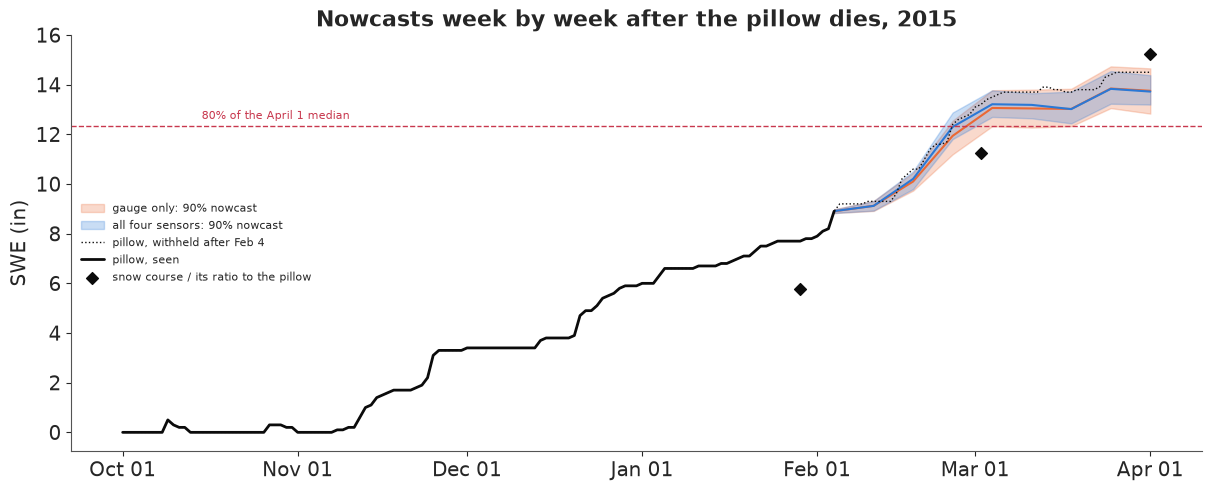

In [19]:
fold_f = jf % 2
pf = pooled_draws([full_fits[fold_f]], n=300)[0]
yP_, mP_ = pillow_until_feb(np.arange(Y) % 2 == fold_f)
m_all, v_all = run_filter(pf, yP_, mP_)[:2]
m_g, v_g = run_filter(pf, yP_, mP_, mD_=0 * obs0["mD"], mC_=0 * obs0["mC"])[:2]


def band(m_, v_, j, rng=np.random.default_rng(3)):
    sims = m_[:, :, j] + np.sqrt(v_[:, :, j]) * rng.normal(size=m_[:, :, j].shape)
    return np.quantile(sims, [0.05, 0.5, 0.95], axis=0)


fig, ax = plt.subplots(figsize=(12, 4.8))
wk = pd.to_datetime(week_end[:, jf])
for (m_, v_), col, lab in (((m_g, v_g), ORANGE, "gauge only"), ((m_all, v_all), BLUE, "all four sensors")):
    qq = band(m_, v_, jf)
    ax.fill_between(wk[LAST:], qq[0, LAST:], qq[2, LAST:], color=col, alpha=0.25, label=f"{lab}: 90% nowcast")
    ax.plot(wk[LAST:], qq[1, LAST:], color=col, lw=1.5)
s = season(FEATURE).loc[:f"{FEATURE}-04-01"]
ax.plot(s.index, s.wteq, color=INK, lw=1, ls=":", label="pillow, withheld after Feb 4")
ax.plot(s.loc[:str(wk[LAST].date())].index, s.loc[:str(wk[LAST].date())].wteq, color=INK, lw=2,
        label="pillow, seen")
cf = course[(course.date > f"{FEATURE-1}-10-01") & (course.date <= f"{FEATURE}-04-01")]
lam_hat = full_fits[fold_f].posterior["lam"].mean(("chain", "draw")).values
ax.scatter(cf.date, cf.swe / lam_hat[[SURVEYS.index(x) for x in cf.survey]], color=INK, marker="D", zorder=5,
           label="snow course / its ratio to the pillow")
ax.axhline(0.8 * MED_APR1, color=RED, lw=1, ls="--")
ax.text(wk[1], 0.8 * MED_APR1 + 0.3, "80% of the April 1 median", color=RED, fontsize=8)
ax.xaxis.set_major_formatter(MONTHS)
ax.set(ylabel="SWE (in)", title=f"Nowcasts week by week after the pillow dies, {FEATURE}")
ax.legend(fontsize=8, loc="center left");

We follow 2015, chosen after seeing the results because it is the season in which the neighbour ratio
makes the wrong call (part 7). The bands are the nowcasts a manager would have had each week, using only
readings up to that week. They start at the last pillow reading and widen as weeks go by without it; the
big storms of late February and March widen them fastest, because that is when the budget is least
certain. Both bands use the same fitted parameters (the all-four fit of the fold in which 2015 was dead);
the orange one simply hides the depth sensor and the course from the filter, so the figure compares what
the sensors add, not two separate fits. With all four sensors (blue) the band is a little narrower than
with the gauge alone (orange) and
tracks the withheld pillow (dotted) slightly better in March. The course surveys, divided by their
estimated ratios, sit about 2 in below the pillow on February 1 and March 1 and 0.7 in above it on April 1,
which is why they pull the band so little. On April 1 both bands say about 13 to 14.5 in, all of it above
the 12.3 in trigger; the pillow said 14.5 in, at the top of the bands.

## 7 · The decision: is April 1 below 80% of median?

The manager's question is a probability: $P(W_{\text{Apr 1}} < 0.8 \times 15.4 \text{ in})$, read off the
predictive distribution. A quick fix gives only a number, which either is or is not below the line.

In [20]:
p_below = {k: norm.cdf((0.8 * MED_APR1 - mm) / ss) for k, (mm, ss) in abl.items()}
dec = pd.DataFrame({"truth %": 100 * truth / MED_APR1,
                    "carry fwd %": 100 * base["carry forward"] / MED_APR1,
                    "persist %": 100 * base["% of median persists"] / MED_APR1,
                    "neighbour %": 100 * base["neighbour ratio"] / MED_APR1,
                    "fusion %": 100 * full_mean / MED_APR1,
                    "P(below 80%)": p_below["all four"]}, index=YEARS)
print(dec.round(2).to_string())

      truth %  carry fwd %  persist %  neighbour %  fusion %  P(below 80%)
2006   117.53        89.61     153.33       128.99    117.89          0.00
2007   109.74        79.22     135.56       111.76    112.65          0.00
2008   101.30        59.09      96.81        96.70     99.86          0.00
2009    91.56        62.34     106.67        90.07     92.76          0.00
2010    74.68        44.16      75.56        73.34     76.34          0.94
2011   127.27        77.92     133.33       133.02    125.38          0.00
2012    73.38        57.79      94.68        58.33     71.19          1.00
2013    70.13        37.66      64.44        68.51     70.47          1.00
2014   154.55        77.27     132.22       155.17    139.92          0.00
2015    94.16        57.79      98.89        78.48     89.33          0.00
2016   112.99        64.94     106.38       108.73    108.67          0.00
2017   125.32        95.45     163.33       117.08    119.45          0.00
2018    95.45        59.0

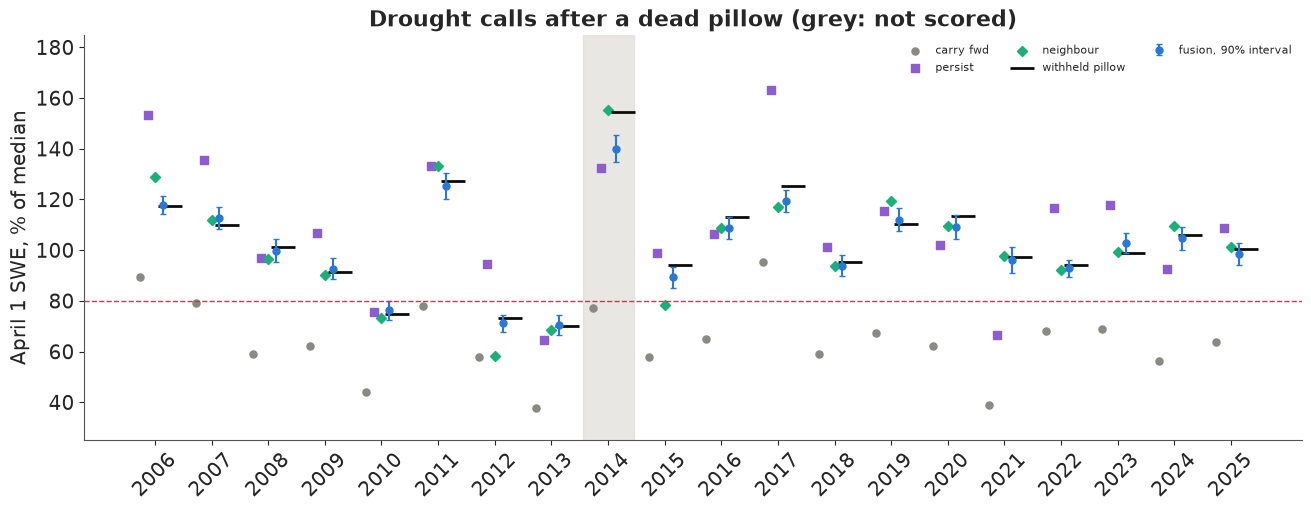

In [21]:
fig, ax = plt.subplots(figsize=(13, 5))
xx = np.arange(Y)
for c, col, mk, off in (("carry fwd %", MUTED, "o", -0.27), ("persist %", PURPLE, "s", -0.13),
                        ("neighbour %", AQUA, "D", 0.0)):
    ax.scatter(xx + off, dec[c], color=col, marker=mk, s=26, label=c.replace(" %", ""))
ax.errorbar(xx + 0.14, dec["fusion %"], yerr=1.645 * 100 * full_sd / MED_APR1, fmt="o", color=BLUE, ms=5,
            capsize=2, label="fusion, 90% interval")
ax.scatter(xx + 0.27, dec["truth %"], color=INK, marker="_", s=300, lw=2, label="withheld pillow")
ax.axhline(80, color=RED, lw=1, ls="--")
for j in np.where(edited)[0]:
    ax.axvspan(j - 0.45, j + 0.45, color=LIGHT, alpha=0.6, zorder=0)
ax.set_xticks(xx, YEARS, rotation=45)
ax.set(ylabel="April 1 SWE, % of median", ylim=(25, 185),
       title="Drought calls after a dead pillow (grey: not scored)")
ax.legend(fontsize=8, ncol=3, loc="upper right");

Every scored season gets the right call from the fused budget, and with conviction: the probability of
being below 80% of median is 0.94 in 2010 (truth 75%), 1.00 in 2012 and 2013 (73% and 70%), and below 0.005
in every other season (printed as 0.00). The three drought seasons are the only ones where it is not
effectively zero or one, and 2010 is the closest to the line in both the forecast (76%) and the truth.

The figure shows where the quick fixes go wrong. Carrying February forward (grey) puts almost every season
below the line. Persistence (purple) misses in both directions and by up to 38 points (2017). The neighbour
ratio (green) is close to the truth in most seasons, but in 2015 its neighbours had a poor February and
March relative to University Camp, and it puts April 1 at 78% of median - a drought call - where the pillow
said 94% and the fused budget 89% (its interval does not cover 94%: 2015 is one of the three misses of
part 5, yet the call is right). In 2012 the neighbour ratio is 15 points low, because one neighbour,
Lake Eldora, lost half its snow in February-March (8.1 to 3.9 in), a reminder that a neighbour's snowpack also has a life of its
own. The fusion's answer differs from the neighbours' because it uses the site's own gauge and depth
sensor, calibrated against the site's own pillow.

## 8 · A real fault: March 2014

So far the pillow died cleanly: its readings just stopped. Real faults are worse, because the sensor keeps
reporting. In 2014 the University Camp pillow did both of the things pillows do. Here is the real-time
record, before NRCS edited it, run through the fitted filter (the fold in which 2014 was dead, so the
parameters never saw a 2014 pillow reading after February 4) with every real-time reading trusted, and the
standardised innovation of each pillow reading.

In [22]:
j14 = list(YEARS).index(2014)
fold14 = j14 % 2
p14 = pooled_draws([full_fits[fold14]], n=300)[0]
s14 = season(2014).loc[:"2014-04-01"]
raw_week = uc.wteq_raw.reindex(pd.to_datetime(week_end[:, j14])).to_numpy()
yP_raw, mP_raw = pillow_until_feb(np.arange(Y) % 2 == fold14)
yP_raw[:, j14], mP_raw[:, j14] = np.nan_to_num(raw_week), np.isfinite(raw_week).astype(float)
z_raw = run_filter(p14, yP_raw, mP_raw)[2]
z_pillow = np.nanmean(z_raw[0][:, :, j14], axis=0)                 # trusting every reading
m_r, v_r = run_filter(p14, yP_raw, mP_raw)[:2]
m_c, v_c, _, _, used = run_filter(p14, yP_raw, mP_raw, gate=4.0)    # ignoring readings beyond 4 sd
for g in (3.0, 5.0, 8.0):                                            # how much does the threshold matter?
    qg = band(*run_filter(p14, yP_raw, mP_raw, gate=g)[:2], j14)
    print(f"gate at {g:.0f} sd: April 1 SWE {qg[1, -1]:.1f} in (90%: {qg[0, -1]:.1f}-{qg[2, -1]:.1f})")
for k in range(LAST - 2, K):
    print(f"week ending {week_end[k, j14]}: real-time {raw_week[k]:5.1f} in, published {pillow[k, j14]:5.1f} in, "
          f"innovation z {z_pillow[k]:+6.1f}, reading used by the gated filter in "
          f"{100 * used[:, k, j14].mean():3.0f}% of draws")
for lab, (m_, v_) in {"every real-time reading trusted": (m_r, v_r), "readings beyond 4 sd ignored": (m_c, v_c)}.items():
    qq = band(m_, v_, j14)
    print(f"{lab}: April 1 SWE {qq[1, -1]:.1f} in (90%: {qq[0, -1]:.1f}-{qq[2, -1]:.1f})")
print(f"published (NRCS-edited) {truth[j14]:.1f} in, real-time {apr1_raw[j14]:.1f} in, "
      f"pillow dead from February: {full_mean[j14]:.1f} +- {full_sd[j14]:.1f} in")

gate at 3 sd: April 1 SWE 21.5 in (90%: 20.9-23.7)
gate at 5 sd: April 1 SWE 23.6 in (90%: 23.3-23.9)
gate at 8 sd: April 1 SWE 23.5 in (90%: 23.2-23.9)
week ending 2014-01-21: real-time   9.2 in, published   9.2 in, innovation z   -0.6, reading used by the gated filter in 100% of draws
week ending 2014-01-28: real-time  10.1 in, published  10.1 in, innovation z   +0.1, reading used by the gated filter in 100% of draws
week ending 2014-02-04: real-time  11.9 in, published  11.9 in, innovation z   +1.8, reading used by the gated filter in 100% of draws
week ending 2014-02-11: real-time  15.7 in, published  15.7 in, innovation z   +5.8, reading used by the gated filter in   0% of draws
week ending 2014-02-18: real-time  17.3 in, published  17.3 in, innovation z   +1.1, reading used by the gated filter in  70% of draws
week ending 2014-02-25: real-time  17.3 in, published  18.3 in, innovation z   -5.2, reading used by the gated filter in  30% of draws
week ending 2014-03-04: real-time  18

The real-time pillow stalled at 17.3 in from February 18 to the beginning of March while the gauge caught
more than an inch (NRCS later raised those days), and then, between March 18 and 21, dropped by 6.3 in
in one step and stayed down - no thaw, no rain, and the depth sensor and gauge saw nothing of the kind.
The innovations say so: the March 25 reading is 46 predictive sds below the budget's prediction, and the
April 1 reading, judged after the filter has been dragged down by the first, is still 6 sds low.

A filter that trusts every reading reports about 17.5 in on April 1, 114% of median; the real-time pillow said
the same. The simplest defence is **innovation gating**: ignore any pillow reading more than 4 predictive
sds from its prediction. The gated filter rejects the drop and reports 23.5 in, within 0.3 in of the value
NRCS published after its own repair, 23.8 in. That agreement is not independent confirmation: both repairs
build on the pillow's readings before the drop (22.7 in on March 18) plus a week of snowfall, so they
agree largely by construction. Still, the answer moved by 6 in. The threshold of 4 sd is a round number,
not tuned on this season, and the first lines of the printout show how much it matters: at 5 or 8 sd
the gated filter gives 23.5-23.6 in, at 3 sd only 21.5 in, because a tighter gate throws away more of the
real February readings. The dead-pillow forecast of part 5, which never saw the
pillow after February 4, said 21.5 ± 0.5 in, more than four of its sds below the published value: in this
big year the gauge-driven budget alone misses badly, and the pillow's own February readings knew that
February storms put more water on it than the gauge suggested.

Gating is crude, and the printout shows its cost. The storm of February 7-9 put 3.8 in on the pillow,
about 6 sds more than the gauge-driven prediction; the gate threw that real reading away in every draw.
Having fallen behind, about 30% of the draws then also rejected the next real readings (February 18 and
March 4), and in those draws the filter ran below the pillow for weeks - hence the long lower tail of the
90% interval on April 1 (from about 21 in up to 23.9 in). A gate cannot tell "the sensor is wrong" from
"the other sensors missed something". The principled version gives the pillow a hidden fault state - a
sticky two-state Markov chain, summed out with the forward algorithm as in E24 - and lets the posterior
weigh a fault against a storm.

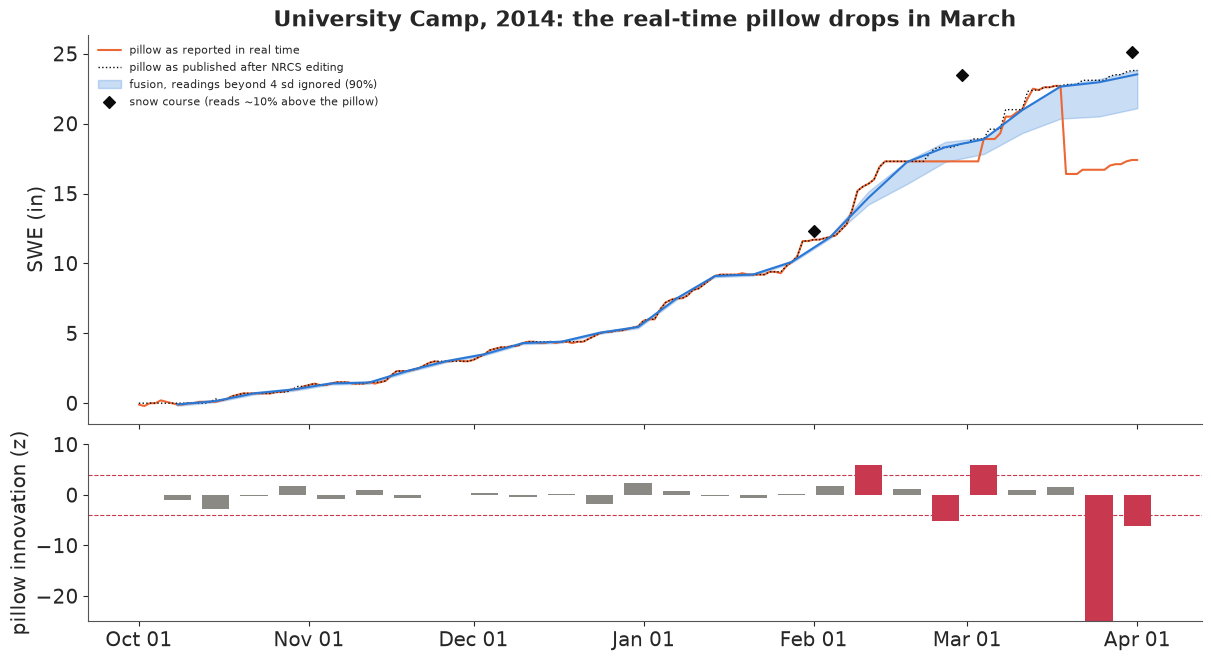

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax = axes[0]
wk14 = pd.to_datetime(week_end[:, j14])
ax.plot(s14.index, s14.wteq_raw, color=ORANGE, lw=1.5, label="pillow as reported in real time")
ax.plot(s14.index, s14.wteq, color=INK, lw=1, ls=":", label="pillow as published after NRCS editing")
qq = band(m_c, v_c, j14)
ax.fill_between(wk14, qq[0], qq[2], color=BLUE, alpha=0.25, label="fusion, readings beyond 4 sd ignored (90%)")
ax.plot(wk14, qq[1], color=BLUE, lw=1.5)
c14 = course[(course.date > "2013-10-01") & (course.date <= "2014-04-01")]
ax.scatter(c14.date, c14.swe, color=INK, marker="D", zorder=5, label="snow course (reads ~10% above the pillow)")
ax.set(ylabel="SWE (in)", title="University Camp, 2014: the real-time pillow drops in March")
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
ax.bar(wk14, z_pillow, width=5, color=np.where(np.abs(z_pillow) > 4, RED, MUTED))
ax.axhline(-4, color=RED, lw=0.8, ls="--"); ax.axhline(4, color=RED, lw=0.8, ls="--")
ax.xaxis.set_major_formatter(MONTHS)
ax.set(ylabel="pillow innovation (z)", ylim=(-25, 10));

The lower panel shows the innovations of the trusting filter (the March 25 bar runs off the scale at
-46). Through autumn and January they stay within ±3, as they should when the pillow works; the red bars
are the five readings beyond ±4. In the upper panel the gated nowcast's median (blue line) follows the
pillow until February, falls behind for a week after the February storm, and then rejoins it; the band's
lower edge - the draws that also rejected later readings - stays below for the rest of the season. In late
March, while the real-time record (orange) falls to 17 in, the gated nowcast goes on to 23.5 in, on top
of NRCS's edited record (dotted).

In [24]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 130 s


## Summary

* **Quick fixes for a dead pillow range from useless to decent.** With the pillow hidden from February 4
  in 19 seasons, carrying the last reading forward misses April 1 by 5.9 in (rmse) and wrongly calls a
  drought in 14 seasons; percent-of-median persistence misses by 2.8 in, depth times February density by
  2.6 in (biased low, because snow gets 11-13% denser between early February and April 1), and the
  neighbour ratio by about 1 in, with
  one wrong drought call (2015).
* **A weekly snow budget as a state-space model** - SWE fed by gauge snowfall through a learned catch
  ratio (0.87), a latent density rising from 0.26, a fresh-snow excess, and a course with its own ratio to
  the pillow (1.10-1.14) - fits 20 seasons in under half a minute per fold with no divergences, because a Kalman
  filter in a `pm.Potential` integrates out the 1,560 weekly states. Its April 1 nowcasts miss by about
  0.45 in and make no wrong drought calls; the drought seasons get probabilities of 0.94-1.00 and the
  others below 0.005.
* **One-week-ahead checks passed while the eight-week forecast was overconfident.** Treating the depth
  sensor's error as short-lived put 13 of 19 truths in the 90% intervals (mean $z^2$ about 1.55); a slowly
  drifting depth error (weekly sd 0.67 in, learned; persistence 0.94 per week, set mostly by its prior)
  brought that to 16 of 19 ($z^2$ 1.2, log score +2 nats), scored on the same seasons that suggested the
  fix. Nineteen seasons cannot tell 16 from 17.
* **At this site the gauge does most of the work.** Gauge alone: rmse 0.48 in with honest intervals;
  adding depth: 0.43 in and the best log score; the course adds nothing to the April 1 nowcast, because it
  differs from the pillow by about 1.2 in. A windier site, or a gauge with its own faults, would change that.
* **The fusion caught a real fault.** In March 2014 the real-time pillow dropped 6.3 in in one step; its
  innovation was -46 sd. Ignoring readings beyond 4 sd moved April 1 from 17.5 to 23.5 in, close to NRCS's
  own edited value (23.8 in; both build on the readings before the drop), but the same gate also
  discarded a real storm. The main limits: one site, a
  two-fold backtest of 19 seasons, the gauge taken as error-free input, and a published record that is
  itself partly edited.

## Try it yourself

1. **A fault state instead of a gate.** Give the pillow a hidden two-state Markov chain (working / faulty,
   with a sticky transition matrix), where a faulty reading is uninformative (a wide normal around the
   last good value). Sum the state out inside the filter (each week, two Kalman updates weighted by the
   state probabilities, then collapse - an interacting-multiple-model filter). Does it keep the February
   2014 storm and reject the March drop?
2. **Lose the gauge too.** Remove the gauge (set the weekly snowfall input to its seasonal average and
   raise $q_0$) and rebuild April 1 from depth and course alone. How much worse is the backtest, and does
   the course start to matter? Repeat at another SNOTEL site with a snow course beside it (the
   `tools/build_e96_data.py` station list is easy to change), such as Jones Pass or Independence Pass.
3. **Pool the neighbours.** Add the four neighbouring pillows as extra windows: each with its own budget
   sharing the weekly snowfall anomalies with University Camp (a common weekly factor in $\eta_k$). Does
   the neighbours' information improve on the gauge in seasons like 2015, or does the 2012 Lake Eldora problem
   come back?

### References

Church, J. E. (1933). Snow surveying: its principles and possibilities. *Geographical Review* 23, 529-563.
Goodison, B. E., Louie, P. Y. T. & Yang, D. (1998). *WMO Solid Precipitation Measurement Intercomparison:
Final Report*. WMO/TD 872. Hock, R. (2003). Temperature index melt modelling in mountain areas. *Journal of
Hydrology* 282, 104-115. Johnson, J. B. & Marks, D. (2004). The detection and correction of snow water
equivalent pressure sensor errors. *Hydrological Processes* 18, 3513-3525. Kalman, R. E. (1960). A new
approach to linear filtering and prediction problems. *Journal of Basic Engineering* 82, 35-45. Rasmussen,
R. et al. (2012). How well are we measuring snow? *Bulletin of the American Meteorological Society* 93,
811-829. Serreze, M. C. et al. (1999). Characteristics of the western United States snowpack from snowpack
telemetry (SNOTEL) data. *Water Resources Research* 35, 2145-2160. Slater, A. G. & Clark, M. P. (2006). Snow
data assimilation via an ensemble Kalman filter. *Journal of Hydrometeorology* 7, 478-493. Sturm, M. et al.
(2010). Estimating snow water equivalent using snow depth data and climate classes. *Journal of
Hydrometeorology* 11, 1380-1394.